In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
from sklearn.datasets import fetch_california_housing

In [11]:
housing = fetch_california_housing(as_frame=True)
housing.target

0        4.526
1        3.585
2        3.521
3        3.413
4        3.422
         ...  
20635    0.781
20636    0.771
20637    0.923
20638    0.847
20639    0.894
Name: MedHouseVal, Length: 20640, dtype: float64

In [36]:
print(housing.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib:
https://lib.stat.cmu.edu/datasets/houses.zip

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block g

In [16]:
housing.data.to_csv('CaliforniaHousing.csv', index=False)
housing.target.to_csv('CaliforniaHousingTarget.csv', index=False)


Text(0.5, 0, 'Median House Value $100k')

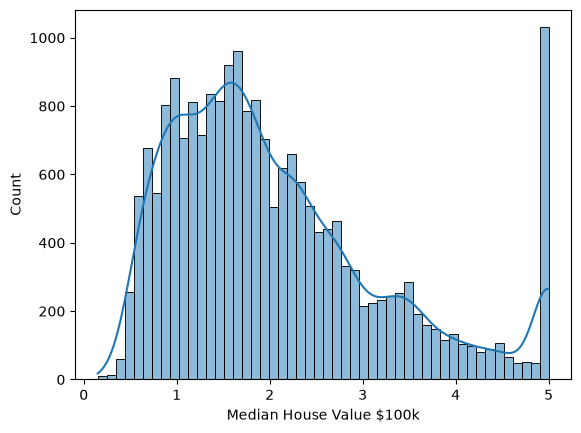

In [24]:
p = sns.histplot(housing.target,bins=50,kde=True)
p.set_xlabel('Median House Value $100k')



In [26]:
housing.data.columns = housing.data.columns.str.lower()
housing.data.isnull().sum()

medinc        0
houseage      0
averooms      0
avebedrms     0
population    0
aveoccup      0
latitude      0
longitude     0
dtype: int64

In [29]:
housing.data.describe()

,medinc,houseage,averooms,avebedrms,population,aveoccup,latitude,longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


In [82]:
n = len(housing.data)
int_val = int(n*0.2)
int_test = int(n*0.2)
int_train = int(n-(int_val+int_test))

int_val,int_test,int_train, int_val+int_test+int_train,n
df_train = housing.data.iloc[:int_train]
df_val = housing.data.iloc[int_train:int_train+int_val]
df_test = housing.data.iloc[int_train+int_val:]

y_train = housing.target.iloc[:int_train]
y_val = housing.target.iloc[int_train:int_train+int_val]
y_test = housing.target.iloc[int_train+int_val:]

df_train.reset_index(inplace=True)
df_val.reset_index(inplace=True)
df_test.reset_index(inplace=True)

int_val,int_test,int_train, int_val+int_test+int_train,n

(4128, 4128, 12384, 20640, 20640)

In [88]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [93]:
flds = ['medinc','houseage','averooms','avebedrms','population','aveoccup']
X_train = df_train[flds].values

w0, w = train_linear_regression(X_train, y_train)

In [94]:
y_pred = w0+X_train.dot(w)

<Axes: xlabel='MedHouseVal', ylabel='Count'>

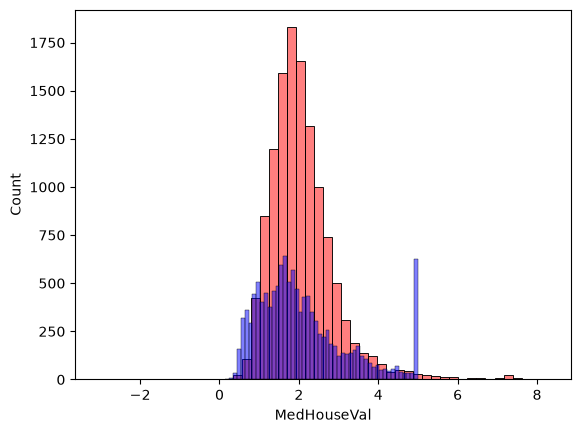

In [95]:
sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

In [97]:
y_train

0        4.526
1        3.585
2        3.521
3        3.413
4        3.422
         ...  
12379    0.830
12380    1.225
12381    1.136
12382    1.345
12383    1.213
Name: MedHouseVal, Length: 12384, dtype: float64